<a href="https://colab.research.google.com/github/Pranav-Kumar14/Handwriting-Image-Detection/blob/main/Handwriting_Image_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

100.0%


[MLP (Non-CNN)] Epoch 1/2, Loss: 2.1277
[MLP (Non-CNN)] Epoch 2/2, Loss: 1.5242

=== MLP (Non-CNN) Evaluation Results ===
Accuracy: 58.01%
              precision    recall  f1-score   support

           0      0.326     0.536     0.405        28
           1      0.583     0.737     0.651        38
           2      0.842     0.485     0.615        33
           3      0.500     0.514     0.507        35
           4      0.821     0.719     0.767        32
           5      0.379     0.658     0.481        38
           6      0.350     0.269     0.304        26
           7      0.676     0.605     0.639        38
           8      0.353     0.529     0.424        34
           9      0.600     0.618     0.609        34
          10      0.406     0.520     0.456        25
          11      0.246     0.410     0.308        39
          12      0.872     0.723     0.791        47
          13      0.759     0.550     0.638        40
          14      0.667     0.821     0.736       

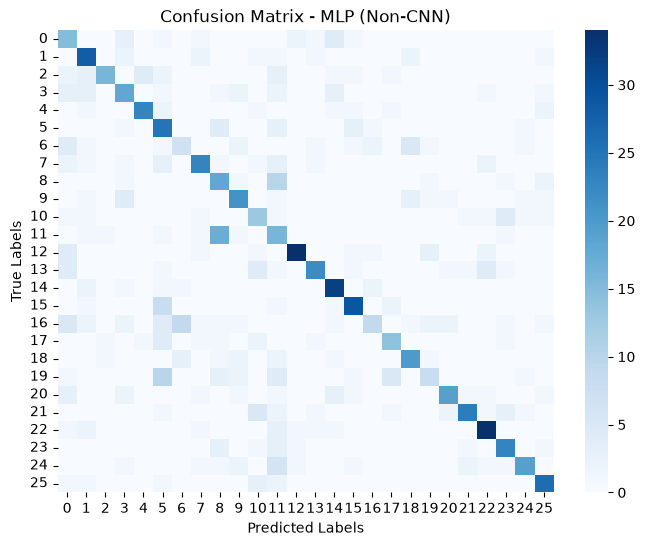

[EnhancedCNN (Your Model)] Epoch 1/2, Loss: 1.5114
[EnhancedCNN (Your Model)] Epoch 2/2, Loss: 0.7378

=== EnhancedCNN (Your Model) Evaluation Results ===
Accuracy: 82.36%
              precision    recall  f1-score   support

           0      0.667     0.857     0.750        28
           1      0.929     0.684     0.788        38
           2      0.968     0.909     0.938        33
           3      0.871     0.771     0.818        35
           4      1.000     0.875     0.933        32
           5      0.914     0.842     0.877        38
           6      0.550     0.423     0.478        26
           7      0.762     0.842     0.800        38
           8      0.560     0.824     0.667        34
           9      0.962     0.735     0.833        34
          10      0.786     0.880     0.830        25
          11      0.833     0.385     0.526        39
          12      0.977     0.915     0.945        47
          13      0.769     0.750     0.759        40
          14     

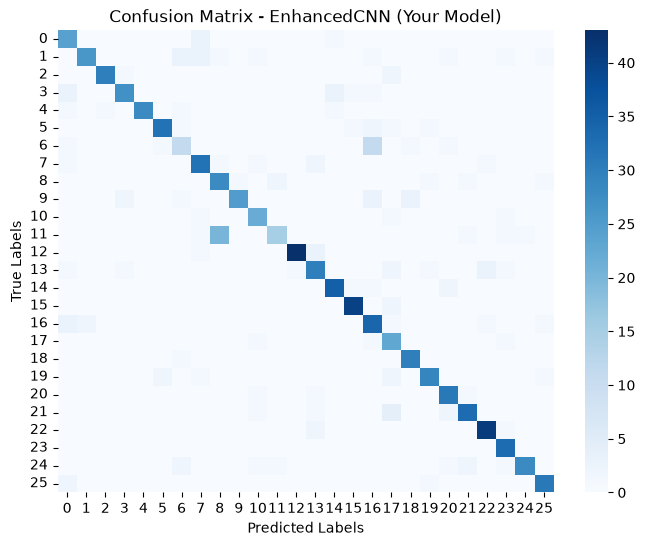

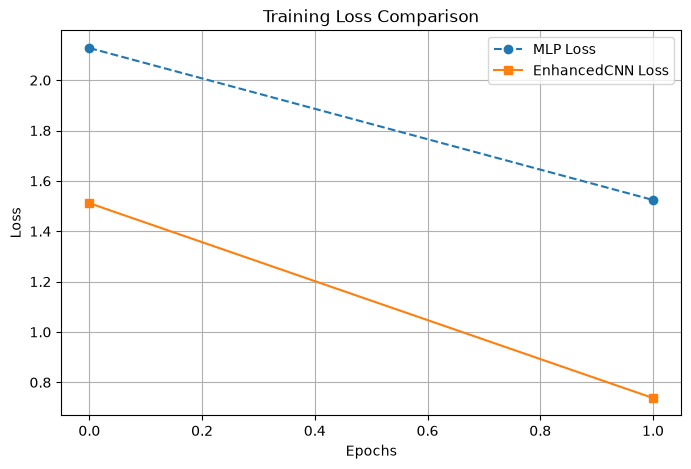

C:\Users\TANMAY SHARMA\AppData\Local\Temp\ipykernel_12296\1413406040.py:180: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='Model', y='Accuracy (%)', palette=['gray', 'purple'])


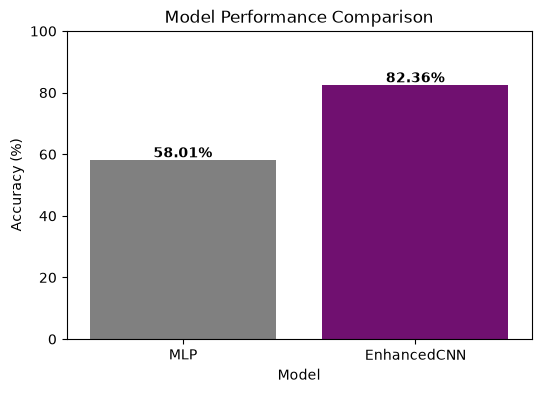

Trained CNN model saved successfully.


In [2]:
import torch
from torch.utils.data import DataLoader, ConcatDataset, random_split, Subset
from torchvision import datasets, transforms
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

data_dir = "./data"
batch_size = 64
num_epochs = 2
learning_rate = 1e-3
random_seed = 42
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

torch.manual_seed(random_seed)
np.random.seed(random_seed)

transform_train = transforms.Compose([
    transforms.Grayscale(),
    transforms.RandomRotation(10),
    transforms.RandomAffine(0, translate=(0.1, 0.1)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])
transform_test = transforms.Compose([
    transforms.Grayscale(),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

train_dataset = datasets.EMNIST(
    root=data_dir,
    split='letters',
    train=True,
    download=True,
    transform=transform_train
)

test_dataset = datasets.EMNIST(
    root=data_dir,
    split='letters',
    train=False,
    download=True,
    transform=transform_test
)

# Limit training data to 10,000 samples for faster testing
train_dataset = Subset(
    train_dataset,
    range(min(10000, len(train_dataset)))
)

full_dataset = ConcatDataset([train_dataset, test_dataset])
portion_size = int(0.3 * len(full_dataset))
unused_size = len(full_dataset) - portion_size
subset_30_percent, _ = random_split(full_dataset, [portion_size, unused_size], generator=torch.Generator().manual_seed(random_seed))

train_size = int(0.9 * len(subset_30_percent))
test_size = len(subset_30_percent) - train_size
new_train_subset, new_test_subset = random_split(subset_30_percent, [train_size, test_size], generator=torch.Generator().manual_seed(random_seed))

train_loader = DataLoader(new_train_subset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(new_test_subset, batch_size=batch_size, shuffle=False)

class MLP(nn.Module):
  def __init__(self):
    super(MLP, self).__init__()
    self.fc1 = nn.Linear(28*28, 512)
    self.fc2 = nn.Linear(512, 128)
    self.fc3 = nn.Linear(128, 27)

  def forward(self, x):
    x = x.view(x.size(0), -1)
    x = F.relu(self.fc1(x))
    x = F.dropout(x, 0.3)
    x = F.relu(self.fc2(x))
    x = self.fc3(x)
    return x

class EnhancedCNN(nn.Module):
    def __init__(self):
        super(EnhancedCNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 32, 3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        self.dropout = nn.Dropout(0.4)
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 27)

    def forward(self, x):
        x = F.relu(self.bn1(self.conv1(x)))
        x = F.max_pool2d(x, 2)
        x = F.relu(self.bn2(self.conv2(x)))
        x = F.max_pool2d(x, 2)
        x = x.view(x.size(0), -1)
        x = self.dropout(x)
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

def train_and_evaluate(model, model_name):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)
    scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.5)

    train_losses = []
    for epoch in range(num_epochs):
        model.train()
        running_loss = 0
        for images, labels in train_loader:
            images, labels = images.to(device), (labels - 1).to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
        scheduler.step()
        epoch_loss = running_loss / len(train_loader)
        train_losses.append(epoch_loss)
        print(f"[{model_name}] Epoch {epoch+1}/{num_epochs}, Loss: {epoch_loss:.4f}")

    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), (labels - 1).to(device)
            outputs = model(images)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    acc = np.mean(np.array(all_preds) == np.array(all_labels))
    print(f"\n=== {model_name} Evaluation Results ===")
    print(f"Accuracy: {acc*100:.2f}%")
    print(classification_report(all_labels, all_preds, digits=3))

    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(8,6))
    sns.heatmap(cm, annot=False, cmap='Blues')
    plt.title(f'Confusion Matrix - {model_name}')
    plt.xlabel('Predicted Labels')
    plt.ylabel('True Labels')
    plt.show()

    return model, acc, train_losses, cm, (all_labels, all_preds)

mlp_model, acc_mlp, loss_mlp, cm_mlp, pred_data_mlp = train_and_evaluate(
    MLP(), "MLP (Non-CNN)"
)

cnn_model, acc_cnn, loss_cnn, cm_cnn, pred_data_cnn = train_and_evaluate(
    EnhancedCNN(), "EnhancedCNN (Your Model)"
)

plt.figure(figsize=(8,5))
plt.plot(loss_mlp, label="MLP Loss", linestyle='--', marker='o')
plt.plot(loss_cnn, label="EnhancedCNN Loss", linestyle='-', marker='s')
plt.title("Training Loss Comparison")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

data = {
    'Model': ['MLP', 'EnhancedCNN'],
    'Accuracy (%)': [acc_mlp*100, acc_cnn*100]
}
df = pd.DataFrame(data)

plt.figure(figsize=(6,4))
sns.barplot(data=df, x='Model', y='Accuracy (%)', palette=['gray', 'purple'])
plt.title("Model Performance Comparison")
plt.ylim(0, 100)
for i, v in enumerate(df['Accuracy (%)']):
    plt.text(i, v + 1, f"{v:.2f}%", ha='center', fontweight='bold')
plt.show()

torch.save(cnn_model.state_dict(), "enhanced_emnist_cnn_best.pth")
print("Trained CNN model saved successfully.")




========== EMNIST Dataset Statistics ==========
Total images in full EMNIST dataset: 145600
30% subset size: 43680
  ↳ Train split (90%): 39312
  ↳ Test split (10%):  4368

Label Distribution (Train):
Letter A: 1492
Letter B: 1518
Letter C: 1558
Letter D: 1532
Letter E: 1491
Letter F: 1512
Letter G: 1538
Letter H: 1488
Letter I: 1500
Letter J: 1483
Letter K: 1513
Letter L: 1505
Letter M: 1488
Letter N: 1485
Letter O: 1550
Letter P: 1529
Letter Q: 1549
Letter R: 1545
Letter S: 1556
Letter T: 1488
Letter U: 1488
Letter V: 1453
Letter W: 1529
Letter X: 1514
Letter Y: 1523
Letter Z: 1485


C:\Users\TANMAY SHARMA\AppData\Local\Temp\ipykernel_12296\2613555588.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=[chr(u + 64) for u in unique], y=counts, palette="viridis")


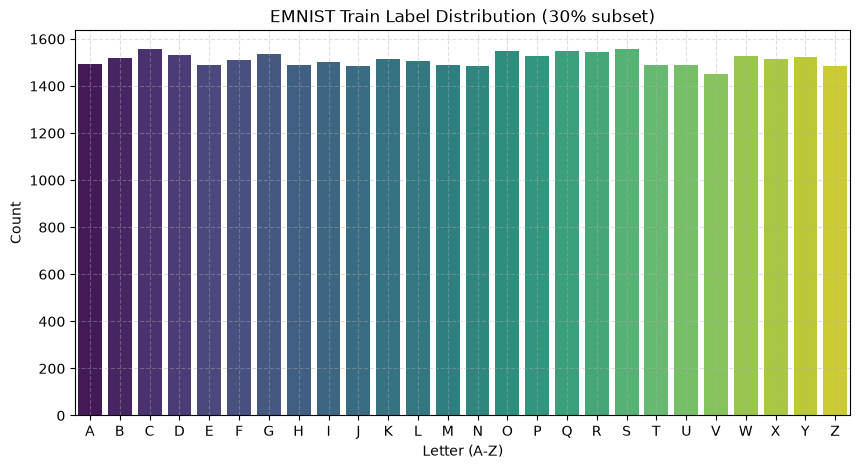

In [3]:
import torch
from torch.utils.data import ConcatDataset, random_split
from torchvision import datasets, transforms
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

data_dir = "./data"
random_seed = 42
torch.manual_seed(random_seed)
np.random.seed(random_seed)

transform_train = transforms.Compose([
    transforms.Grayscale(),
    transforms.RandomRotation(10),
    transforms.RandomAffine(0, translate=(0.1, 0.1)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

transform_test = transforms.Compose([
    transforms.Grayscale(),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

train_dataset = datasets.EMNIST(root=data_dir, split='letters', train=True, download=True, transform=transform_train)
test_dataset = datasets.EMNIST(root=data_dir, split='letters', train=False, download=True, transform=transform_test)

# Combine train and test
full_dataset = ConcatDataset([train_dataset, test_dataset])
full_len = len(full_dataset)

portion_size = int(0.3 * full_len)
unused_size = full_len - portion_size
subset_30_percent, _ = random_split(full_dataset, [portion_size, unused_size], generator=torch.Generator().manual_seed(random_seed))

train_size = int(0.9 * len(subset_30_percent))
test_size = len(subset_30_percent) - train_size
new_train_subset, new_test_subset = random_split(subset_30_percent, [train_size, test_size], generator=torch.Generator().manual_seed(random_seed))

print("\n========== EMNIST Dataset Statistics ==========")
print(f"Total images in full EMNIST dataset: {full_len}")
print(f"30% subset size: {len(subset_30_percent)}")
print(f"  ↳ Train split (90%): {train_size}")
print(f"  ↳ Test split (10%):  {test_size}")

def get_labels(dataset):
    labels = []
    for data, label in dataset:
        labels.append(int(label))
    return np.array(labels)

train_labels = get_labels(new_train_subset)
test_labels = get_labels(new_test_subset)

print("\nLabel Distribution (Train):")
unique, counts = np.unique(train_labels, return_counts=True)
for u, c in zip(unique, counts):
    print(f"Letter {chr(u + 64)}: {c}")

plt.figure(figsize=(10,5))
sns.barplot(x=[chr(u + 64) for u in unique], y=counts, palette="viridis")
plt.title("EMNIST Train Label Distribution (30% subset)")
plt.xlabel("Letter (A-Z)")
plt.ylabel("Count")
plt.grid(True, linestyle="--", alpha=0.4)
plt.show()
